# Bank Marketing — Customer Subscription Prediction

## 1. Problem Definition & Project Objective

### Problem Statement

The objective of this project is to predict whether a bank
customer will subscribe to a term deposit based on customer
and marketing campaign information.

### Machine Learning Objective

This is a supervised binary classification problem where the
target variable `y` indicates whether the customer subscribed
to a term deposit.

### Business Objective

The model aims to identify customers who are more likely to
subscribe to a term deposit, potentially enabling more
targeted marketing campaigns.

## 2. Import Libraries

We use Pandas to load and inspect the dataset and NumPy for numerical operations that may be needed during analysis.

In [ ]:
import pandas as pd
import numpy as np 

## 3. Load Dataset

The Bank Marketing dataset contains customer, financial, and marketing campaign information. We use `bank-full.csv` as our primary dataset because it contains 45,211 records.

The file uses a semicolon (`;`) as its field separator.

In [4]:
df = pd.read_csv("../data/bank-full.csv", sep=";")

df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Data Understanding

Before performing data cleaning and exploratory data analysis, we inspect the dataset's structure, variables, data types, and basic quality.

### 4.1 Dataset Shape

We inspect the number of records and columns to understand the size of our dataset.

In [5]:
df.shape

(45211, 17)

The dataset contains 45,211 rows and 17 columns. These columns consist of 16 input features and one target variable.

### 4.2 Dataset Information

We inspect the column names, non-null counts, data types, and memory usage.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


The dataset contains numerical and categorical variables. The non-null counts help us identify columns with missing values, while the data types guide our later preprocessing decisions.

### 4.3 Column Names

We list the column names to identify the available input variables and target.

In [7]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

The dataset contains customer attributes, account information, contact details, and campaign history. The `y` column is our target variable.

### 4.4 Numerical and Categorical Features

We identify the numerical and categorical input features so that suitable preprocessing can be applied later.

In [8]:
numerical_features = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]

categorical_features = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome"
]

target = "y"

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Target:", target)

Numerical features: 7
Categorical features: 9
Target: y


The dataset contains seven numerical features and nine categorical features. The target `y` indicates whether a customer subscribed to the term deposit. We will use these feature groups when building the preprocessing pipeline.

### 4.5 Missing Values

We check each column for missing values before deciding whether any imputation is required.

In [9]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

The initial inspection shows no missing values in the dataset. Therefore, missing-value imputation is not required based on this check.

### 4.6 Duplicate Records

We check for completely duplicated rows to determine whether exact duplicate records are present.

In [10]:
df.duplicated().sum()

np.int64(0)

No completely duplicated rows were found. Therefore, duplicate-row removal is not required based on this check.

### 4.7 Target Distribution

We inspect the number and percentage of records belonging to each target class to understand the distribution of subscription outcomes.

In [11]:
target_counts = df[target].value_counts()

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

Target counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


The target is imbalanced because non-subscriptions are substantially more frequent than subscriptions. We will consider this when evaluating models and will not rely on accuracy alone.

### 4.8 Descriptive Statistics

We summarize the numerical features to obtain an initial view of their ranges, central values, and variability.

In [12]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


The summary provides statistics such as the mean, standard deviation, quartiles, minimum, and maximum. We will investigate distributions and unusual values more closely during EDA.

### 4.9 Unique Values

We count the distinct values in each column to understand the variety of values present, particularly in categorical features.

In [13]:
df.nunique()

age            77
job            12
marital         3
education       4
default         2
balance      7168
housing         2
loan            2
contact         3
day            31
month          12
duration     1573
campaign       48
pdays         559
previous       41
poutcome        4
y               2
dtype: int64

The number of unique values helps us understand categorical feature cardinality and plan preprocessing. Unique-value counts alone do not determine which encoding technique should be used.

### 4.10 Important Observations

The initial inspection establishes the following:

- The primary dataset contains 45,211 records and 17 columns.
- It has 16 input features and one target variable, `y`.
- The input features include numerical and categorical variables.
- No missing values or completely duplicated rows were found.
- The target classes are imbalanced, with approximately 88.3% `no` and 11.7% `yes`.
- The `pdays` feature uses `-1` to represent customers who were not previously contacted.

These findings guide the next stages of data cleaning and exploratory data analysis.

## 5. Data Cleaning

Before performing exploratory data analysis, we inspect the dataset for data-quality issues such as missing values, duplicate records, unexpected numerical values, and inconsistent categorical labels.

We will apply transformations only when the observed data and domain knowledge justify them.

### 5.1 Data Quality Audit

We perform an initial audit of missing values, duplicate records, and dataset dimensions. These checks help us determine whether basic cleaning operations are necessary.

In [ ]:
# Store the original dataset dimensions
original_shape = df.shape

# Count missing values
total_missing = df.isnull().sum().sum()

# Count completely duplicated rows
total_duplicates = df.duplicated().sum()

print("Original dataset shape:", original_shape)
print("Total missing values:", total_missing)
print("Duplicate rows:", total_duplicates)

The initial audit found no null values or completely duplicated rows. Therefore, neither null-value imputation nor duplicate-row removal is currently required based on these checks. We will continue inspecting other potential data-quality issues.

### 5.2 Categorical Value Inspection

We inspect the distinct values and their frequencies in categorical columns. This helps identify placeholder categories such as `unknown` and potential inconsistencies in category labels.

In [ ]:
for column in categorical_features + [target]:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))

Review the output for unexpected labels, literal `unknown` values, and inconsistent categories. A value such as `unknown` is not automatically a null value, so we will not delete or replace it without justification.

### 5.3 Numerical Range Inspection

We inspect descriptive statistics and selected numerical conditions to identify values that may require investigation. Unusual values are not automatically errors; their meaning must be considered.

In [ ]:
df[numerical_features].describe().T

In [ ]:
print("Age below 18:", (df["age"] < 18).sum())
print("Negative balance:", (df["balance"] < 0).sum())
print("Negative duration:", (df["duration"] < 0).sum())
print("Negative campaign:", (df["campaign"] < 0).sum())
print("pdays equal to -1:", (df["pdays"] == -1).sum())

These checks help identify values that deserve further investigation.

- A negative account balance may be valid.
- A negative duration or campaign count would require investigation.
- The value `pdays = -1` represents a customer who was not previously contacted.

We will not remove records solely because a value is negative or unusually large.

### 5.4 Text Consistency Checks

We check whether categorical values contain leading or trailing whitespace. Such inconsistencies can cause logically identical categories to be treated as different values.

In [ ]:
for column in categorical_features + [target]:
    values = df[column].dropna().astype(str)

    whitespace_count = values.ne(values.str.strip()).sum()

    print(f"{column}: {whitespace_count} values with surrounding whitespace")

If inconsistencies are found, we will inspect them before applying normalization. If the audit finds no whitespace issues, no whitespace-cleaning operation is necessary.

### 5.5 Cleaning Decisions

The cleaning strategy is based on the results of our audit.

- Missing values: handle only if present.
- Duplicate rows: remove only if duplicates are confirmed and removal is justified.
- Unknown categories: inspect their meaning before deciding how to handle them.
- Unusual numerical values: verify their meaning before modifying them.
- Inconsistent text: normalize only when an inconsistency is confirmed.
- `pdays = -1`: preserve its documented meaning.

No unnecessary transformations will be applied merely to make the dataset appear cleaner.

In [ ]:
cleaning_audit = {
    "original_shape": original_shape,
    "missing_values": total_missing,
    "duplicate_rows": total_duplicates,
}

cleaning_audit

### 5.6 Verification

After applying any justified cleaning operation, we recheck the dataset dimensions, missing values, and duplicate rows to verify the result.

No rows or values are removed by the audit cells above.

In [ ]:
print("Current dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

The audit has not modified the dataset. The initial checks found no null values or exact duplicate rows. Any further cleaning operation will be performed only if the remaining inspections establish a genuine issue.

# 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distributions of customer and campaign features and investigate how subscription outcomes vary across different groups.

We use a focused set of visualizations to identify meaningful patterns and potential issues before feature engineering and model development.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 6.1 Target Distribution

We examine the number of subscribers and non-subscribers to understand the balance between the two target classes.

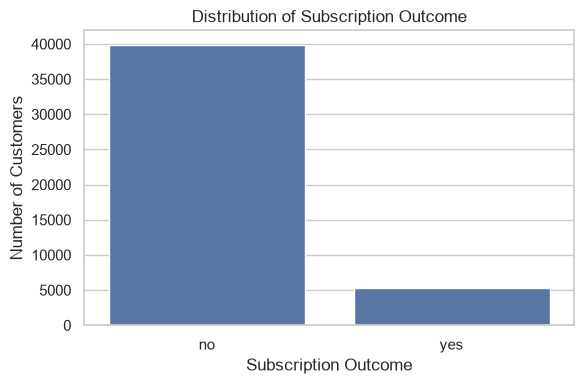

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=target)

plt.title("Distribution of Subscription Outcome")
plt.xlabel("Subscription Outcome")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [16]:
target_percentages = (
    df[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

target_percentages

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

The target distribution shows the relative frequency of subscribers and non-subscribers. Use the displayed percentages to describe the class imbalance. This observation will guide our choice of evaluation metrics later.

### 6.2 Numerical Feature Distributions

We inspect selected numerical features to understand their ranges, spread, and skewness. These plots may reveal patterns that deserve further investigation.

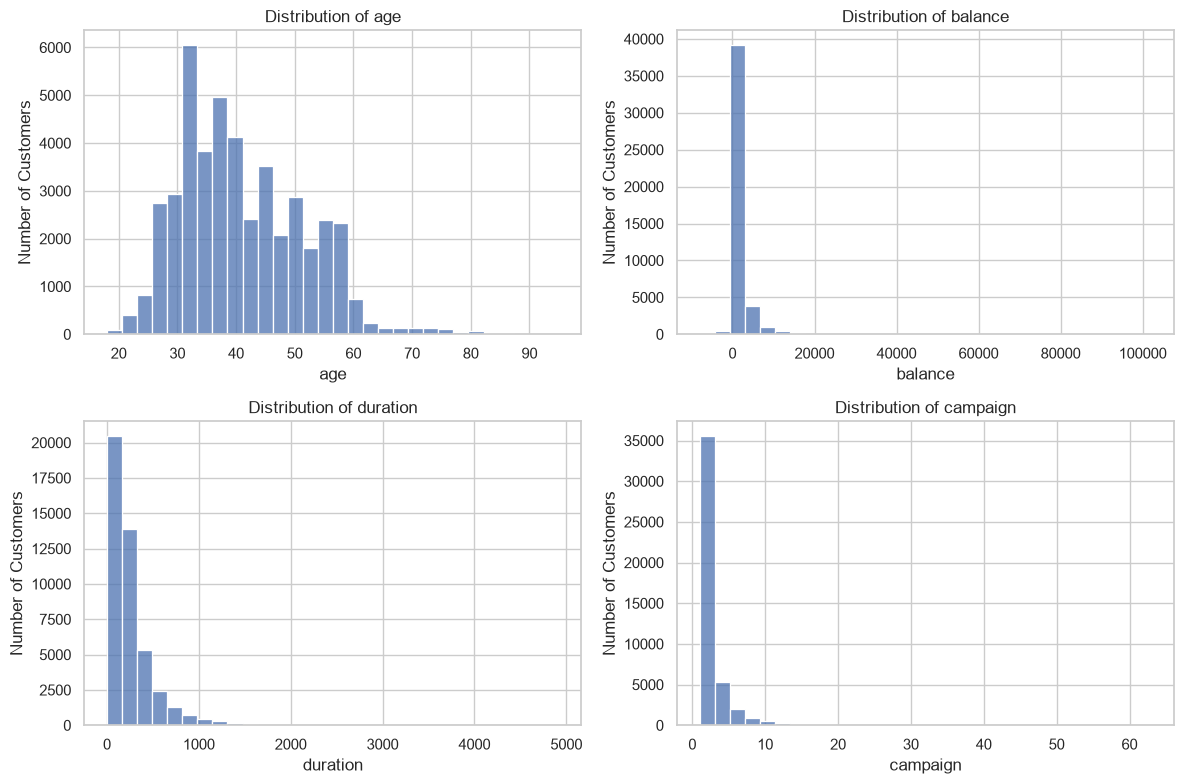

In [17]:
selected_numerical = ["age", "balance", "duration", "campaign"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, selected_numerical):
    sns.histplot(data=df, x=column, bins=30, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Review each histogram and record the patterns actually visible, such as concentration, spread, skewness, or unusual values. Do not assume that an extreme value is invalid without investigating its meaning.

### 6.3 Categorical Feature Distributions

We inspect selected categorical variables to understand the sizes of their categories and identify common or rare groups.

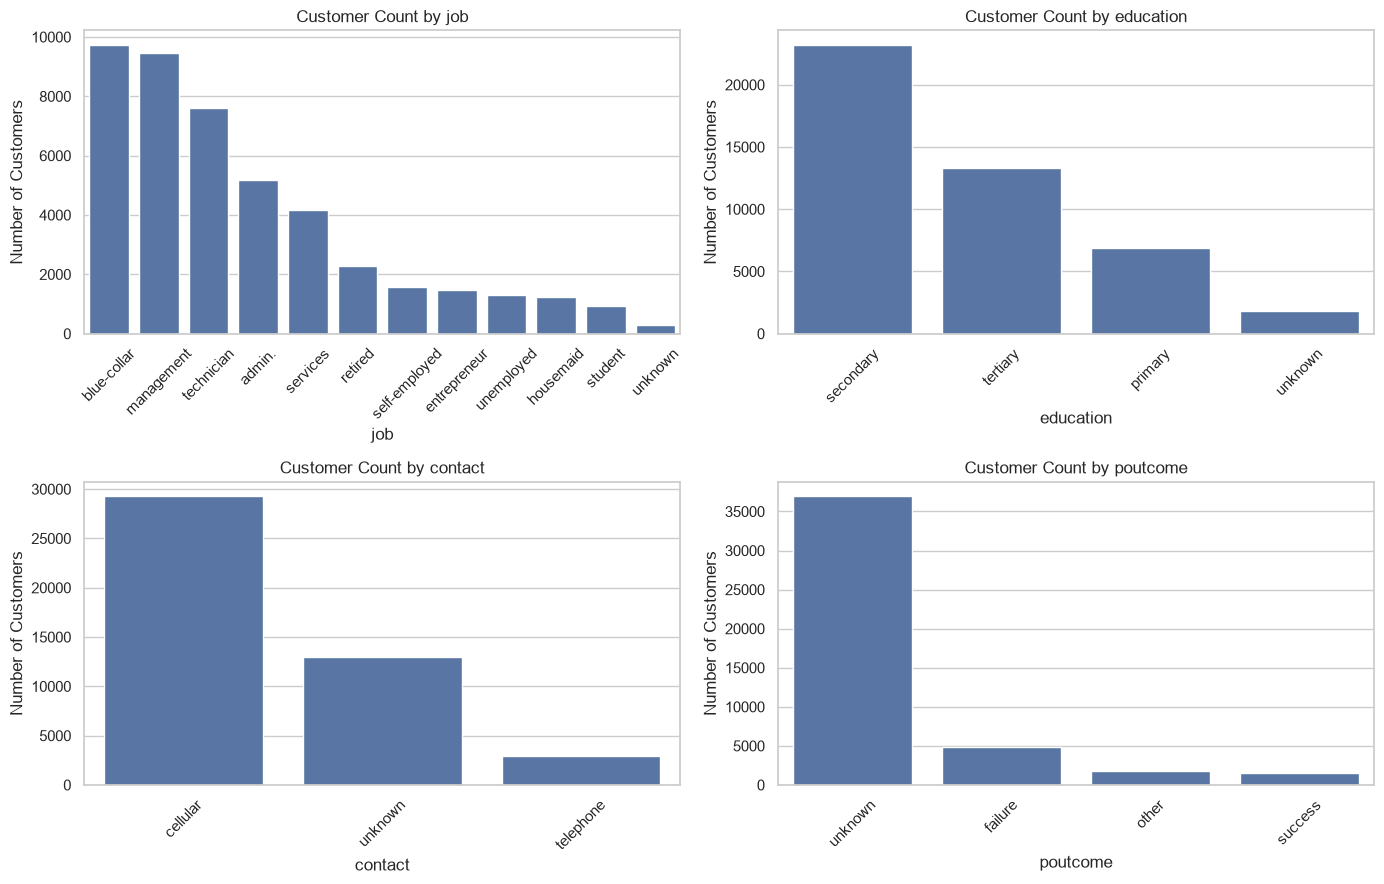

In [18]:
selected_categorical = ["job", "education", "contact", "poutcome"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flat, selected_categorical):
    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        order=order,
        ax=ax
    )

    ax.set_title(f"Customer Count by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The count plots show how customers are distributed across the selected categories. Category frequency does not directly indicate the likelihood of subscription; we investigate subscription rates separately.

### 6.4 Subscription Rate by Categorical Features

Raw counts can be misleading when categories have different numbers of customers. We calculate the percentage of customers who subscribed within each category to make more meaningful comparisons.

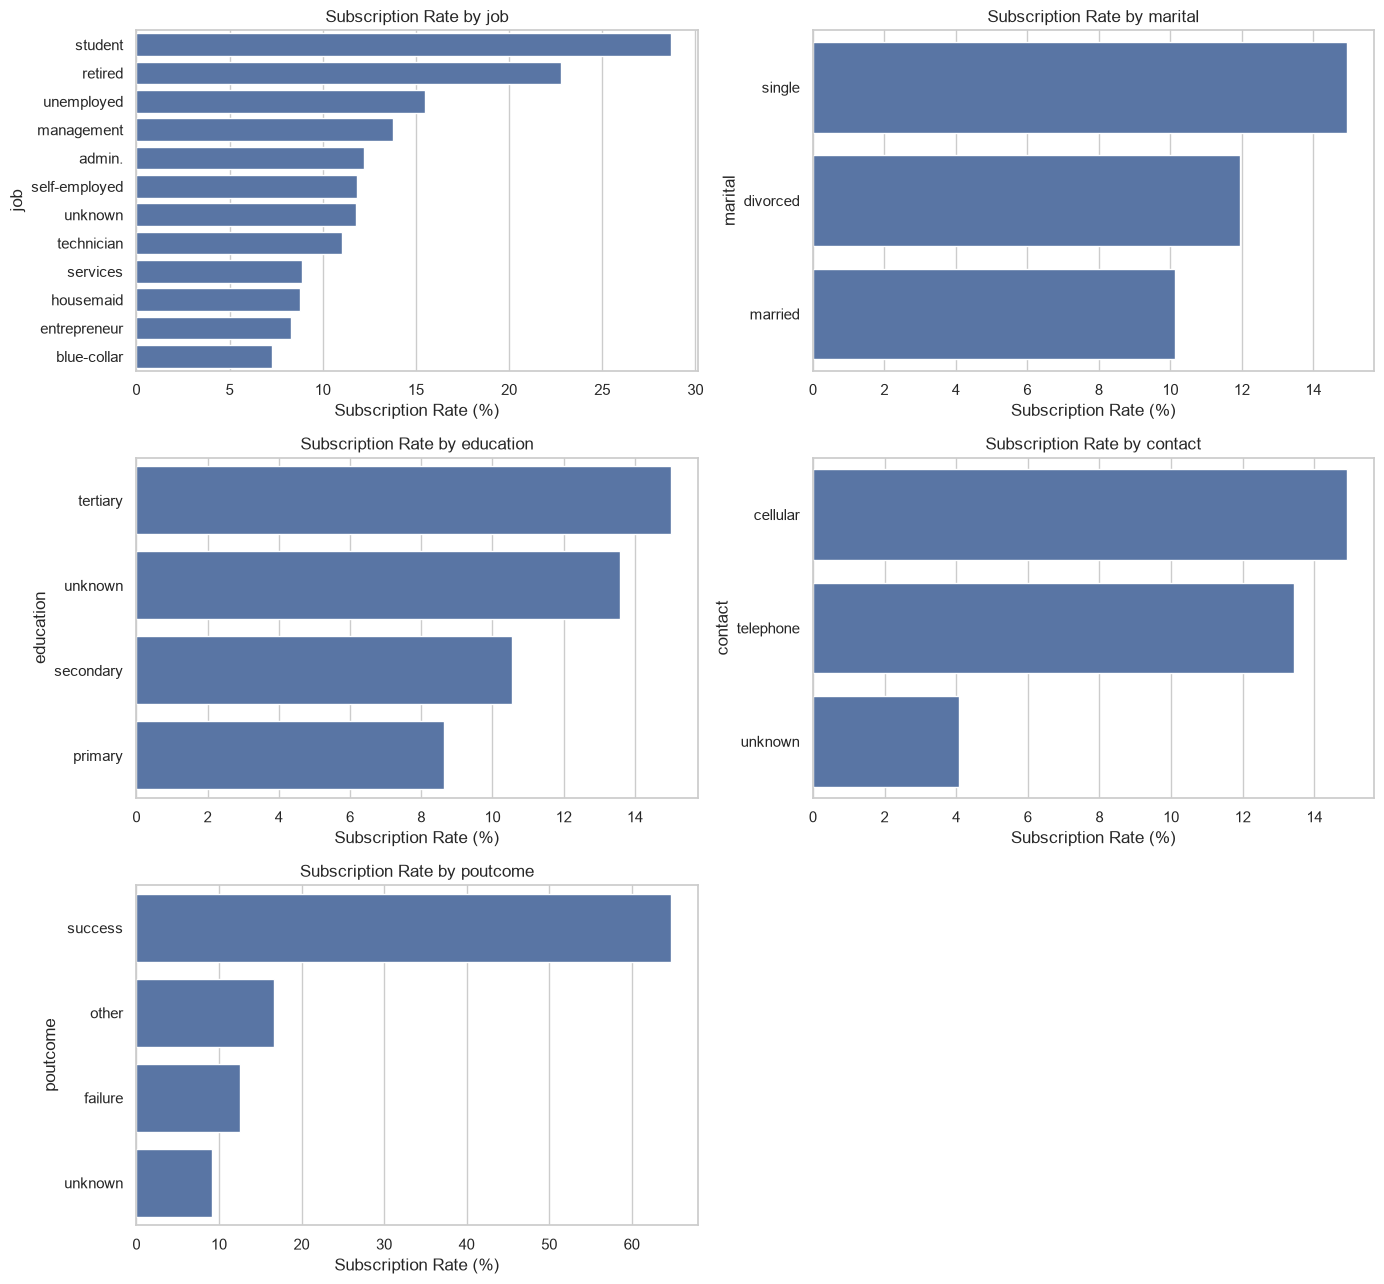

In [19]:
selected_rate_features = ["job", "marital", "education", "contact", "poutcome"]

df_eda = df.assign(
    subscribed=(df[target] == "yes").astype(int)
)

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for ax, column in zip(axes.flat, selected_rate_features):
    rates = (
        df_eda.groupby(column)["subscribed"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.values,
        y=rates.index,
        ax=ax
    )

    ax.set_title(f"Subscription Rate by {column}")
    ax.set_xlabel("Subscription Rate (%)")
    ax.set_ylabel(column)

# Remove the unused sixth subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
plt.show()

Compare the observed subscription rates across categories. Record only the differences supported by the actual plots. These are descriptive associations and do not establish that a category causes a customer to subscribe.

### 6.5 Numerical Features by Subscription Outcome

We compare selected numerical features across the two subscription outcomes to investigate whether their distributions differ.

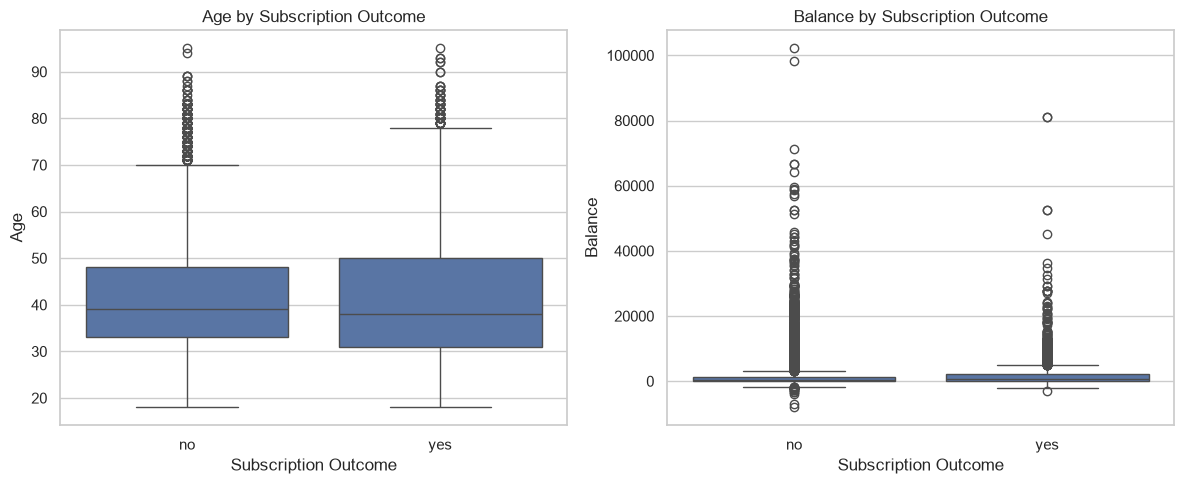

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x=target, y="age", ax=axes[0])
axes[0].set_title("Age by Subscription Outcome")
axes[0].set_xlabel("Subscription Outcome")
axes[0].set_ylabel("Age")

sns.boxplot(data=df, x=target, y="balance", ax=axes[1])
axes[1].set_title("Balance by Subscription Outcome")
axes[1].set_xlabel("Subscription Outcome")
axes[1].set_ylabel("Balance")

plt.tight_layout()
plt.show()

The box plots compare the medians, spread, and potential extreme observations of age and balance across subscription outcomes. Interpret the visible differences cautiously; the plots do not prove causation or establish predictive importance by themselves.

### 6.6 EDA Summary

Summarize the findings supported by the plots:

- Target class distribution and imbalance.
- Important observations from selected numerical distributions.
- Differences in customer category frequencies.
- Differences in observed subscription rates across selected groups.
- Potential data-quality or modeling considerations requiring further investigation.

These observations will guide feature engineering and model development. They should be based on the actual outputs rather than assumptions made before plotting.

# 7. Feature Engineering

Feature engineering creates or transforms input variables to represent useful information for a machine learning model. We will introduce features only when they have a clear interpretation and a justified role in our project.

### 7.1 Previous Contact Indicator

The `pdays` column uses `-1` to represent customers who were not previously contacted. We create a binary feature to explicitly represent whether a previous contact was recorded.

In [ ]:
df["previously_contacted"] = (
    df["pdays"] != -1
).astype(int)   

The new feature uses `0` when `pdays` equals `-1` and `1` otherwise. We retain the original `pdays` column because it also contains information about the time since a previous contact.

In [ ]:
df[["pdays", "previously_contacted"]].head(10)

In [ ]:
df["previously_contacted"].value_counts()

The counts show how many records have a previous contact recorded and how many do not. Interpret the actual output rather than assuming the class frequencies.

### 7.2 Feature Verification

We verify that the new feature contains only binary values and correctly represents the original `pdays` condition.

In [ ]:
assert df["previously_contacted"].isin([0, 1]).all()

assert (
    df["previously_contacted"]
    == (df["pdays"] != -1).astype(int)
).all()

print("Feature created and verified.")
print("Dataset shape:", df.shape)

The verification checks confirm that `previously_contacted` is binary and consistent with the original `pdays` values. The original feature and target remain unchanged.

### 7.3 Feature Engineering Decisions

We retain both `pdays` and `previously_contacted` for now. We will evaluate their usefulness during model development rather than assuming the derived feature improves performance.

We will also review `duration` against the intended prediction time. A feature should only be used if it would legitimately be available when the prediction is made.

Encoding categorical variables and scaling numerical variables will be handled in the preprocessing stage.

# 8. Train-Test Split

We divide the dataset into training and test subsets. The training set will be used to fit our models, while the test set will remain held out for final evaluation.

### 8.1 Separate Features and Target

The input features (`X`) contain the variables used for prediction. The target (`y`) contains the subscription outcome we want to predict.

In [ ]:
X = df.drop(columns=[target])
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

### 8.2 Split the Dataset

We use an 80:20 split, a fixed random seed for reproducibility, and stratification to preserve approximately the same target-class proportions in both subsets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 8.3 Inspect Split Dimensions

We inspect the dimensions of the four resulting objects to confirm that the data was divided as expected.

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

### 8.4 Compare Target Distributions

We compare the target percentages in the training and test subsets to verify that stratification preserved approximately the original class proportions.

In [ ]:
print("Training target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

The target proportions should be similar in both subsets. Stratification preserves the approximate class balance; it does not make the two classes equally frequent.

### 8.5 Verify the Split

We check that the subsets account for all records, that training and test indices do not overlap, and that the feature rows remain aligned with their target labels.

In [ ]:
assert len(X_train) + len(X_test) == len(X)

assert X_train.index.intersection(X_test.index).empty

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("Train-test split verified successfully.")

The verification checks confirm that the split accounts for all records, the training and test indices do not overlap, and each feature subset remains aligned with its corresponding target labels. Preprocessing will be fitted using the training data only.